# Actividad 1 · Flujo del conocimiento en Softtek
#Sistemas y tecnologías de administración del conocimiento

**Isaac Esquivel Ruiz**  
**AL07003035**




## 1. Consulta a una herramienta de IA

**Herramienta:** ChatGPT.  
**Evidencia:** se conserva el prompt de la actividad y la respuesta generada para este notebook.

**Prompt utilizado**

> Act as a knowledge management consultant. Briefly describe a real or fictitious technology company dedicated to software development, telecom, digital services, or IT support. Explain its line of business, its main operational activities, and the areas where key knowledge is generated (for example: development, technical support, operations, or management). Include examples of how knowledge is generated or used within these areas. The description should be clear and brief so it can serve as analytical context in an academic activity on knowledge management.

**Respuesta obtenida de ChatGPT**

“Softtek es una compañía de tecnología fundada en Monterrey, México, en 1982. Su oferta incluye ingeniería de software, gestión de aplicaciones, infraestructura tecnológica y ciberseguridad. Estas actividades permiten tomarla como referencia para analizar cómo se aprovecha el conocimiento en una organización tecnológica.

Para este ejercicio se propone un escenario ficticio de trabajo con Desarrollo, Soporte, Operaciones y Seguridad. Desarrollo genera conocimiento al corregir errores y probar soluciones; Soporte reúne información de incidentes y dudas de usuarios; Operaciones aprende del mantenimiento y recuperación de sistemas; y Seguridad define criterios para proteger accesos e información. Gestión utiliza los reportes de estas áreas para decidir qué mejoras atender primero. Por ejemplo, una falla de acceso puede convertirse en un ticket, después en una guía validada y finalmente en una solución que otros compañeros reutilizan. Esta distribución y sus ejemplos son una simplificación académica, no una descripción verificada de los procesos internos de Softtek.”


**Interpretación**

Elegí Softtek porque permite mantener la relación con la idea que ya venía trabajando en el proyecto.  
Lo que me interesa aquí es entender cómo una solución puede servirle a más personas dentro de una empresa.  
Una falla no solo genera trabajo: también deja información y experiencia que se pueden aprovechar después.  
Por eso voy a seguir un ejemplo de acceso a una cuenta y ver qué pasa con lo que aprende cada equipo.  
Los casos son inventados para el ejercicio, así que no los tomo como evidencia de problemas reales de Softtek.  
La respuesta de la IA me sirve como punto de partida; el análisis se desarrolla en las siguientes secciones.


## 2. Preparación
Solo se utilizan Pandas y Matplotlib, disponibles normalmente en Colab. Esta celda importa las herramientas y crea una carpeta para los resultados.


In [1]:
from pathlib import Path
import textwrap
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display, HTML

salida = Path('resultados_actividad_softtek')
salida.mkdir(exist_ok=True)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'text.color': 'black',
                     'axes.labelcolor': 'black', 'axes.edgecolor': 'black'})
pd.set_option('display.max_colwidth', None)
def mostrar_tabla(df):
    estilo = "<style>.tabla-actividad table{border-collapse:collapse;width:100%;table-layout:fixed;} .tabla-actividad th,.tabla-actividad td{color:black;background:white;border:1px solid black;padding:8px;text-align:left;vertical-align:top;white-space:normal;overflow-wrap:break-word;}</style>"
    display(HTML(estilo + '<div class="tabla-actividad">' + df.to_html(index=False,escape=True) + '</div>'))


## 3. Dónde se genera conocimiento
Las cuatro áreas del proyecto se mantienen. Gestión aparece como el rol que utiliza sus reportes para decidir prioridades, no como una quinta categoría del clasificador.


In [2]:
areas = pd.DataFrame([
    ['Desarrollo', 'Crear, probar y corregir software',
     'Aprende por qué falla una función y cómo corregirla', 'Código, pruebas y documentación técnica'],
    ['Soporte', 'Atender dudas e incidentes de usuarios',
     'Reconoce síntomas que se repiten y formas de explicar una solución', 'Tickets y guías de atención'],
    ['Operaciones', 'Mantener sistemas disponibles',
     'Aprende qué revisar ante una caída o recuperación', 'Registros, procedimientos y respaldos'],
    ['Seguridad', 'Proteger accesos e información',
     'Valora riesgos y condiciones para autorizar un cambio', 'Políticas de acceso y reportes de revisión'],
    ['Gestión', 'Definir prioridades y coordinar recursos',
     'Relaciona problemas recurrentes con necesidades de mejora', 'Reportes e indicadores resumidos']
], columns=['Área o rol', 'Actividad', 'Conocimiento que genera o usa', 'Ejemplo explícito'])
mostrar_tabla(areas)


Área o rol,Actividad,Conocimiento que genera o usa,Ejemplo explícito
Desarrollo,"Crear, probar y corregir software",Aprende por qué falla una función y cómo corregirla,"Código, pruebas y documentación técnica"
Soporte,Atender dudas e incidentes de usuarios,Reconoce síntomas que se repiten y formas de explicar una solución,Tickets y guías de atención
Operaciones,Mantener sistemas disponibles,Aprende qué revisar ante una caída o recuperación,"Registros, procedimientos y respaldos"
Seguridad,Proteger accesos e información,Valora riesgos y condiciones para autorizar un cambio,Políticas de acceso y reportes de revisión
Gestión,Definir prioridades y coordinar recursos,Relaciona problemas recurrentes con necesidades de mejora,Reportes e indicadores resumidos


**Interpretación**

La tabla muestra que el conocimiento se genera en varias partes y no solamente cuando alguien programa.  
Soporte conoce lo que le pasa al usuario, mientras que Desarrollo puede explicar la causa técnica de una falla.  
Operaciones aporta lo que aprende al mantener funcionando los sistemas y recuperar el servicio.  
Seguridad agrega los criterios para que una solución no termine creando otro problema con los accesos.  
Gestión necesita reunir esa información para decidir qué conviene corregir o enseñar primero.  
Si cada equipo guarda todo por separado, es más difícil que los demás aprovechen lo que ya se aprendió.


## 4. Ciclo de vida del conocimiento
Analizo las cinco fases de esta actividad. Almacenamiento y organización se explican juntas: incluyen tanto guardar la información como clasificarla para encontrarla después.


In [3]:
etapas = [
    {'Etapa': '1. Creación o captura',
     'Flujo entre áreas': 'Usuario → Soporte → Desarrollo y Seguridad',
     'Qué ocurre': 'Se reporta una falla de acceso. El equipo reúne síntomas, registros y una explicación de la causa.',
     'Qué se transfiere': 'Ticket, evidencia del error e hipótesis de diagnóstico',
     'Tácito': 'Experiencia para distinguir una falla de sesión de una contraseña incorrecta',
     'Explícito': 'Ticket y registros del sistema',
     'IA': 'Propuesta: resumir el ticket y preparar un borrador de solución para revisión'},
    {'Etapa': '2. Almacenamiento o documentación',
     'Flujo entre áreas': 'Desarrollo y Seguridad → Base compartida',
     'Qué ocurre': 'Se escribe la solución validada y se guarda con responsable, fecha y versión.',
     'Qué se transfiere': 'Guía revisada, pruebas y condiciones para aplicar la solución',
     'Tácito': 'Criterio para elegir los pasos y advertencias que necesita otro técnico',
     'Explícito': 'Guía de solución y evidencia de pruebas',
     'IA': 'Propuesta: convertir las notas técnicas en un borrador con una estructura común'},
    {'Etapa': '3. Organización o clasificación',
     'Flujo entre áreas': 'Responsables de áreas → Catálogo de la base',
     'Qué ocurre': 'La guía se relaciona con acceso, autenticación y el área de Soporte; se vincula con la política de Seguridad.',
     'Qué se transfiere': 'Documento etiquetado y relaciones entre temas',
     'Tácito': 'Juicio para decidir cuándo un documento corresponde a más de un área',
     'Explícito': 'Categorías, etiquetas y relaciones del catálogo',
     'IA': 'Propuesta: sugerir categorías con TF-IDF y un clasificador revisado por personas'},
    {'Etapa': '4. Intercambio o transferencia',
     'Flujo entre áreas': 'Base y especialistas → Soporte y Operaciones',
     'Qué ocurre': 'Los compañeros consultan la guía y un especialista explica cuándo utilizarla.',
     'Qué se transfiere': 'Procedimiento escrito y recomendaciones basadas en experiencia',
     'Tácito': 'Consejos y habilidades que se comparten al acompañar a otro compañero',
     'Explícito': 'Guía recuperada y material de capacitación',
     'IA': 'Propuesta: ayudar a recuperar guías mediante búsqueda de información'},
    {'Etapa': '5. Aplicación',
     'Flujo entre áreas': 'Soporte y Operaciones → Usuario',
     'Qué ocurre': 'Se confirma que la guía corresponde al caso y se aplica el procedimiento autorizado.',
     'Qué se transfiere': 'Solución aplicada, verificación y registro de atención',
     'Tácito': 'Criterio para adaptar los pasos y reconocer cuándo conviene escalar el caso',
     'Explícito': 'Lista de verificación y registro del resultado',
     'IA': 'El especialista conserva la decisión de aplicar o escalar; no se automatizan cambios'},
    {'Etapa': '6. Actualización o retroalimentación',
     'Flujo entre áreas': 'Usuario y Soporte → Gestión, Desarrollo y base',
     'Qué ocurre': 'Se revisa si la solución funcionó, se corrige la guía y se detectan problemas recurrentes.',
     'Qué se transfiere': 'Comentarios, recurrencias y nueva versión de la guía',
     'Tácito': 'Reflexión sobre lo que falló y lo que conviene cambiar',
     'Explícito': 'Historial de cambios y reporte de incidentes',
     'IA': 'Propuesta: agrupar reportes parecidos y detectar patrones para apoyar decisiones'}
]
# Agrupo guardar y clasificar en una fase, como indica la Actividad 1.
etapas[1] = {
    'Etapa': '2. Almacenamiento u organización',
    'Flujo entre áreas': 'Desarrollo y Seguridad → Base compartida → Catálogo',
    'Qué ocurre': 'Se guarda una guía validada con responsable, fecha y versión. Se clasifica en Soporte y se vincula con autenticación y la política de Seguridad.',
    'Qué se transfiere': 'Guía revisada, pruebas, etiquetas y relaciones entre temas',
    'Tácito': 'Criterio para explicar los pasos y decidir cómo relacionar el documento con temas y áreas',
    'Explícito': 'Guía validada, categorías, etiquetas e historial de versiones',
    'IA': 'Propuesta: estructurar el borrador y sugerir categorías, con revisión humana'
}
etapas.pop(2)
for numero, etapa in enumerate(etapas, start=1):
    etapa['Etapa'] = str(numero) + '. ' + etapa['Etapa'].split('. ', 1)[1]
ciclo = pd.DataFrame(etapas)
mostrar_tabla(ciclo[['Etapa', 'Flujo entre áreas', 'Qué ocurre', 'Qué se transfiere']])


Etapa,Flujo entre áreas,Qué ocurre,Qué se transfiere
1. Creación o captura,Usuario → Soporte → Desarrollo y Seguridad,"Se reporta una falla de acceso. El equipo reúne síntomas, registros y una explicación de la causa.","Ticket, evidencia del error e hipótesis de diagnóstico"
2. Almacenamiento u organización,Desarrollo y Seguridad → Base compartida → Catálogo,"Se guarda una guía validada con responsable, fecha y versión. Se clasifica en Soporte y se vincula con autenticación y la política de Seguridad.","Guía revisada, pruebas, etiquetas y relaciones entre temas"
3. Intercambio o transferencia,Base y especialistas → Soporte y Operaciones,Los compañeros consultan la guía y un especialista explica cuándo utilizarla.,Procedimiento escrito y recomendaciones basadas en experiencia
4. Aplicación,Soporte y Operaciones → Usuario,Se confirma que la guía corresponde al caso y se aplica el procedimiento autorizado.,"Solución aplicada, verificación y registro de atención"
5. Actualización o retroalimentación,"Usuario y Soporte → Gestión, Desarrollo y base","Se revisa si la solución funcionó, se corrige la guía y se detectan problemas recurrentes.","Comentarios, recurrencias y nueva versión de la guía"


**Interpretación**

Aquí se ve que guardar una solución no es suficiente para que realmente sea útil.  
Primero hay que entender el problema, después documentarlo y luego acomodar la información para encontrarla.  
En almacenamiento y organización incluyo guardar y clasificar, porque un archivo puede existir y aun así ser difícil de encontrar.  
La transferencia también necesita comunicación entre compañeros, sobre todo cuando una guía deja dudas.  
El conocimiento se aprovecha cuando alguien lo usa para atender un caso y comprueba el resultado.  
La última etapa regresa al inicio porque los comentarios y las fallas nuevas pueden cambiar lo que ya sabíamos.


## 5. Conocimiento tácito y explícito en cada etapa
El tácito depende de la experiencia, habilidades y criterio de las personas. El explícito se puede consultar en documentos, registros o repositorios.


In [4]:
mostrar_tabla(ciclo[['Etapa', 'Tácito', 'Explícito']])


Etapa,Tácito,Explícito
1. Creación o captura,Experiencia para distinguir una falla de sesión de una contraseña incorrecta,Ticket y registros del sistema
2. Almacenamiento u organización,Criterio para explicar los pasos y decidir cómo relacionar el documento con temas y áreas,"Guía validada, categorías, etiquetas e historial de versiones"
3. Intercambio o transferencia,Consejos y habilidades que se comparten al acompañar a otro compañero,Guía recuperada y material de capacitación
4. Aplicación,Criterio para adaptar los pasos y reconocer cuándo conviene escalar el caso,Lista de verificación y registro del resultado
5. Actualización o retroalimentación,Reflexión sobre lo que falló y lo que conviene cambiar,Historial de cambios y reporte de incidentes


**Interpretación**

La diferencia que identifico es que saber hacer algo no es lo mismo que tenerlo escrito.  
Un técnico puede reconocer una falla por experiencia, aunque todavía no exista una guía que la explique.  
Cuando documenta sus pasos, una parte de ese conocimiento se vuelve explícita y otros pueden consultarla.  
Aun así, el documento no reemplaza completamente el criterio que se necesita para resolver un caso distinto.  
Por eso aparecen los dos tipos de conocimiento en todas las etapas, aunque cambie la forma de usarlos.  
Para mí, la mejor combinación es tener información clara y también oportunidades para aprender de los compañeros.


## 6. Dónde puede ayudar la IA
Estas son propuestas conceptuales. El código presenta el análisis, pero no ejecuta un modelo generativo, un clasificador ni una búsqueda semántica.


In [5]:
apoyos_ia = pd.DataFrame([
    ['Captura y documentación', 'Ticket resuelto y notas del especialista',
     'Un modelo de lenguaje podría resumir síntomas, causa y pasos en un borrador de guía.',
     'Guía propuesta que conserva el vínculo con el ticket',
     'El especialista revisa exactitud y retira datos sensibles antes de publicar'],
    ['Organización', 'Documentos que una persona ya clasificó',
     'TF-IDF representaría el texto y un clasificador aprendería a sugerir una de las cuatro áreas del proyecto.',
     'Categoría sugerida para un documento nuevo',
     'Una persona corrige etiquetas ambiguas y verifica la clasificación'],
    ['Transferencia', 'Consulta del usuario y documentos autorizados',
     'El proyecto empezaría con TF-IDF y coseno. Una mejora con embeddings podría recuperar textos por cercanía de significado.',
     'Guías relacionadas con su fuente y versión',
     'El usuario revisa la fuente; se respetan permisos y no se inventa una solución'],
    ['Retroalimentación', 'Tickets, resultados y comentarios',
     'La IA podría agrupar descripciones parecidas y señalar problemas que se repiten.',
     'Grupos de incidentes para revisar causas y necesidades de capacitación',
     'Gestión compara frecuencia, impacto y riesgo antes de decidir']
], columns=['Etapa', 'Información de entrada', 'Cómo funcionaría', 'Resultado esperado', 'Revisión humana'])
mostrar_tabla(apoyos_ia)


Etapa,Información de entrada,Cómo funcionaría,Resultado esperado,Revisión humana
Captura y documentación,Ticket resuelto y notas del especialista,"Un modelo de lenguaje podría resumir síntomas, causa y pasos en un borrador de guía.",Guía propuesta que conserva el vínculo con el ticket,El especialista revisa exactitud y retira datos sensibles antes de publicar
Organización,Documentos que una persona ya clasificó,TF-IDF representaría el texto y un clasificador aprendería a sugerir una de las cuatro áreas del proyecto.,Categoría sugerida para un documento nuevo,Una persona corrige etiquetas ambiguas y verifica la clasificación
Transferencia,Consulta del usuario y documentos autorizados,El proyecto empezaría con TF-IDF y coseno. Una mejora con embeddings podría recuperar textos por cercanía de significado.,Guías relacionadas con su fuente y versión,El usuario revisa la fuente; se respetan permisos y no se inventa una solución
Retroalimentación,"Tickets, resultados y comentarios",La IA podría agrupar descripciones parecidas y señalar problemas que se repiten.,Grupos de incidentes para revisar causas y necesidades de capacitación,"Gestión compara frecuencia, impacto y riesgo antes de decidir"


**Interpretación**

Veo más útil la IA en tareas que se repiten, como resumir tickets, sugerir etiquetas o localizar una guía.  
Eso permitiría que el personal dedique más tiempo a revisar la solución y atender los casos difíciles.  
La clasificación y la búsqueda conectan esta actividad con las dos funciones que planteé para el proyecto.  
También distingo que TF-IDF compara vocabulario y no entiende todos los sinónimos como lo haría una búsqueda con embeddings.  
Un resumen o una sugerencia puede estar equivocado, por eso debe conservar su fuente y pasar por revisión.  
La IA apoyaría la organización del conocimiento, pero las decisiones técnicas y las prioridades seguirían en manos del equipo.


## 7. Ejemplo de retroalimentación para decidir
Se usan **12 tickets inventados** para mostrar cómo un registro se convierte en información para una decisión.
Las categorías ya están escritas a mano: este conteo con Pandas **no es una clasificación realizada por IA**.


Problema,Cantidad,Porcentaje
Acceso a la cuenta,6,50.0
Respaldos,3,25.0
Error de aplicación,2,16.7
Permisos,1,8.3


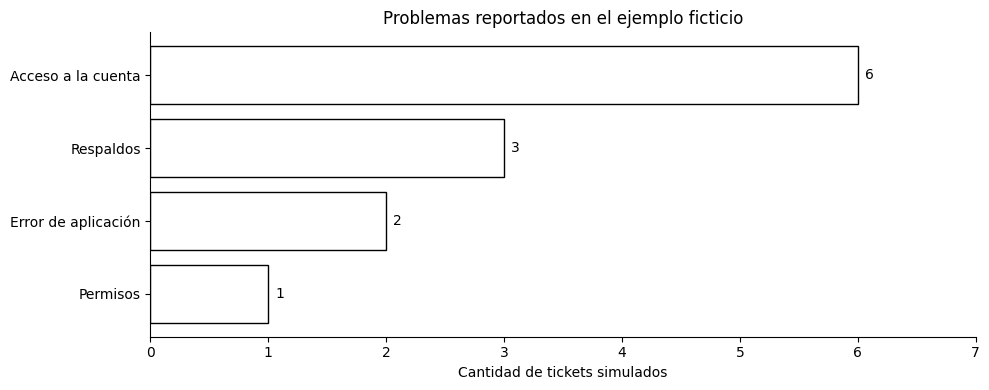

In [6]:
tipos = (['Acceso a la cuenta'] * 6 + ['Respaldos'] * 3
         + ['Error de aplicación'] * 2 + ['Permisos'] * 1)
tickets = pd.DataFrame({'Ticket': [f'T-{i:03d}' for i in range(1, 13)],
                        'Problema': tipos})
resumen = tickets.groupby('Problema', sort=False).size().reset_index(name='Cantidad')
resumen['Porcentaje'] = (100 * resumen['Cantidad'] / len(tickets)).round(1)
mostrar_tabla(resumen)

fig, ax = plt.subplots(figsize=(10, 4))
barras = ax.barh(resumen['Problema'], resumen['Cantidad'], color='white', edgecolor='black')
ax.invert_yaxis()
ax.bar_label(barras, padding=5, color='black')
ax.set_xlim(0, 7)
ax.set_xlabel('Cantidad de tickets simulados')
ax.set_title('Problemas reportados en el ejemplo ficticio')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(salida / 'tickets_simulados.png', dpi=160, bbox_inches='tight')
plt.show()


**Interpretación**

En este ejemplo, seis de los doce tickets corresponden a problemas de acceso, es decir, la mitad del total.  
Eso me haría revisar primero si la guía de acceso está clara o si hay una falla que se está repitiendo.  
Los respaldos aparecen tres veces y los errores de aplicación dos, así que también merecen seguimiento.  
El caso de permisos solo aparece una vez, pero podría ser urgente si afecta la seguridad de la información.  
Por eso no decidiría únicamente por la cantidad: también revisaría el impacto y el riesgo de cada problema.  
Estos números son simulados y el conteo es directo; una IA podría ayudar después a agrupar tickets que estén escritos de formas distintas.


## 8. Diagrama del ciclo de vida
**T = conocimiento tácito · E = conocimiento explícito · IA = apoyo propuesto.**  
Las cajas muestran las etapas; las flechas indican qué información pasa de una a otra y entre qué equipos circula.


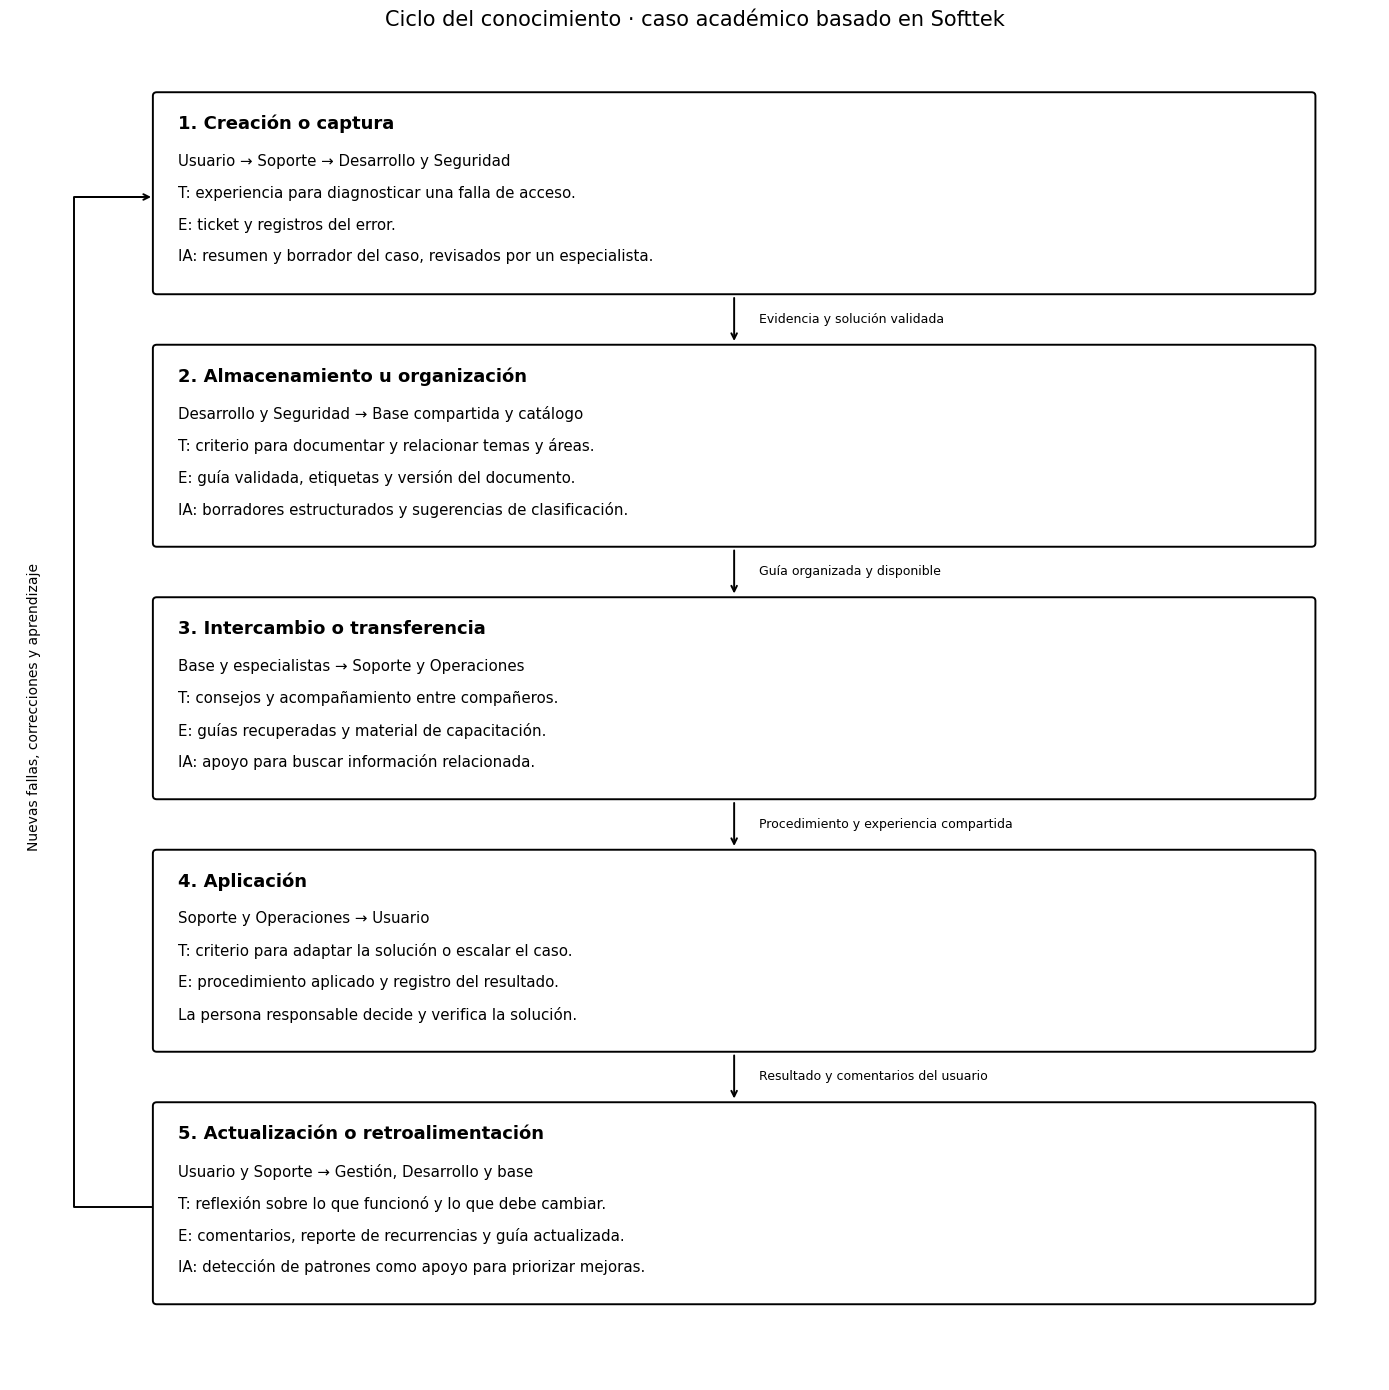

In [7]:
fig, ax = plt.subplots(figsize=(14, 14))
ax.set_xlim(0, 14)
ax.set_ylim(0, 14.3)
ax.axis('off')
ancho, alto = 11.8, 2.08
x = 1.5
ys = [11.65, 8.95, 6.25, 3.55, 0.85]
titulos = ['1. Creación o captura', '2. Almacenamiento o documentación',
           '3. Organización o clasificación', '4. Intercambio o transferencia',
           '5. Aplicación', '6. Actualización o retroalimentación']
contenido = [
    ['Usuario → Soporte → Desarrollo y Seguridad', 'T: experiencia para diagnosticar una falla de acceso.',
     'E: ticket y registros del error.', 'IA: resumen y borrador del caso, revisados por un especialista.'],
    ['Desarrollo y Seguridad → Base compartida', 'T: criterio para explicar pasos y condiciones de uso.',
     'E: guía validada, pruebas, responsable y versión.', 'IA: apoyo para estructurar la documentación.'],
    ['Responsables de áreas → Catálogo compartido', 'T: juicio para relacionar documentos con áreas y temas.',
     'E: categorías, etiquetas y relaciones entre documentos.', 'IA: sugerencias de clasificación con revisión humana.'],
    ['Base y especialistas → Soporte y Operaciones', 'T: consejos y acompañamiento entre compañeros.',
     'E: guías recuperadas y material de capacitación.', 'IA: apoyo para buscar información relacionada.'],
    ['Soporte y Operaciones → Usuario', 'T: criterio para adaptar la solución o escalar el caso.',
     'E: procedimiento aplicado y registro del resultado.', 'La persona responsable decide y verifica la solución.'],
    ['Usuario y Soporte → Gestión, Desarrollo y base', 'T: reflexión sobre lo que funcionó y lo que debe cambiar.',
     'E: comentarios, reporte de recurrencias y guía actualizada.', 'IA: detección de patrones como apoyo para priorizar mejoras.']
]
# Cinco fases, con almacenamiento y organización en la misma caja.
titulos = ['1. Creación o captura', '2. Almacenamiento u organización',
           '3. Intercambio o transferencia', '4. Aplicación',
           '5. Actualización o retroalimentación']
contenido[1] = [
    'Desarrollo y Seguridad → Base compartida y catálogo',
    'T: criterio para documentar y relacionar temas y áreas.',
    'E: guía validada, etiquetas y versión del documento.',
    'IA: borradores estructurados y sugerencias de clasificación.'
]
contenido.pop(2)
for y, titulo, lineas in zip(ys, titulos, contenido):
    caja = FancyBboxPatch((x, y), ancho, alto, boxstyle='round,pad=0.04',
                         linewidth=1.4, edgecolor='black', facecolor='white')
    ax.add_patch(caja)
    ax.text(x + .22, y + alto - .2, titulo, fontsize=13, weight='bold', va='top')
    for j, linea in enumerate(lineas):
        ax.text(x + .22, y + alto - .62 - j*.34, linea, fontsize=10.8, va='top')
flujos = ['Evidencia y solución validada', 'Guía organizada y disponible',
          'Procedimiento y experiencia compartida', 'Resultado y comentarios del usuario']
for i, etiqueta in enumerate(flujos):
    arriba = ys[i]
    abajo = ys[i+1]+alto
    ax.annotate('', xy=(7.4, abajo+.05), xytext=(7.4, arriba-.05),
                arrowprops=dict(arrowstyle='->', color='black', linewidth=1.4))
    ax.text(7.65, (arriba+abajo)/2, etiqueta, fontsize=9, va='center')
# El regreso al inicio hace visible que es un ciclo, no una lista de pasos.
ax.plot([x-.06, .65, .65, x-.15], [ys[-1]+1, ys[-1]+1, ys[0]+1, ys[0]+1],
        color='black', linewidth=1.4)
ax.annotate('', xy=(x-.03, ys[0]+1), xytext=(.65, ys[0]+1),
            arrowprops=dict(arrowstyle='->', color='black', linewidth=1.4))
ax.text(.25, 7.2, 'Nuevas fallas, correcciones y aprendizaje', rotation=90,
        fontsize=10, ha='center', va='center')
ax.set_title('Ciclo del conocimiento · caso académico basado en Softtek', fontsize=15, pad=12)
fig.tight_layout()
fig.savefig(salida / 'diagrama_ciclo_softtek.png', dpi=180, bbox_inches='tight')
plt.show()


**Interpretación**

El diagrama reúne el recorrido completo y muestra que el conocimiento cambia de forma durante el proceso.  
Al principio puede estar en la experiencia de una persona y luego quedar registrado en un ticket o una guía.  
Las flechas muestran que la información pasa entre equipos y necesita regresar cuando aparece algo que corregir.  
La IA puede ayudar en la captura, la documentación, la clasificación, la búsqueda y la detección de patrones.  
En la aplicación dejé visible la responsabilidad del especialista, porque encontrar una guía no garantiza que sirva para cualquier caso.  
Así entiendo la relación con el proyecto: el sistema debe ayudar a aprovechar lo que se aprende, no solo acumular documentos.


## 9. Cierre de la actividad

Lo principal que me llevo es que el conocimiento necesita circular para que tenga utilidad dentro de la organización.  
Una solución guardada puede ahorrar trabajo, pero solo si está clara, se encuentra fácilmente y sigue vigente.  
La experiencia de las personas y los documentos se complementan; ninguno resuelve todo por sí solo.  
La IA puede facilitar tareas repetitivas, siempre que se revisen sus resultados y se respeten los permisos de acceso.  
Esta actividad explica por qué el clasificador y el buscador del proyecto tendrían sentido dentro de ese flujo.  
Con este análisis puedo explicar el ciclo completo y dónde ayudaría la IA sin depender de una grabación.


